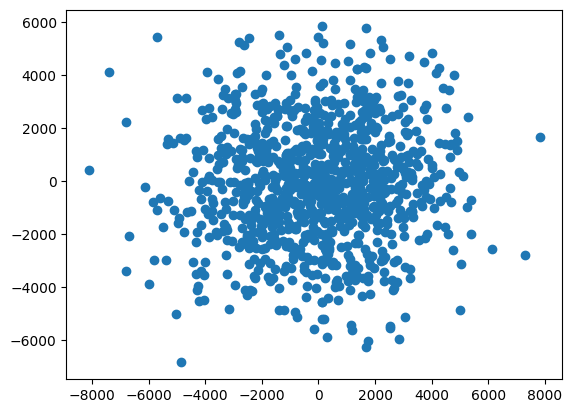

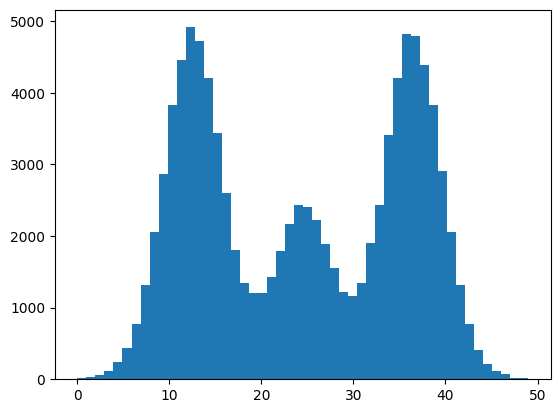

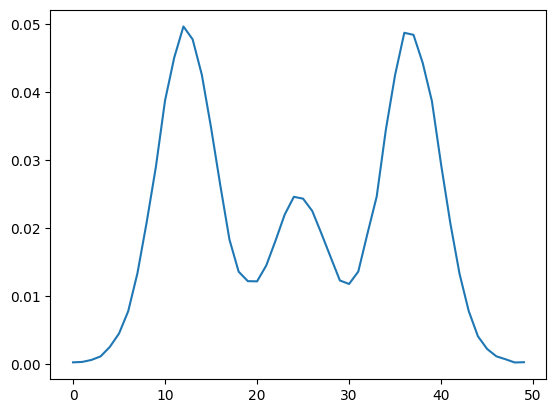

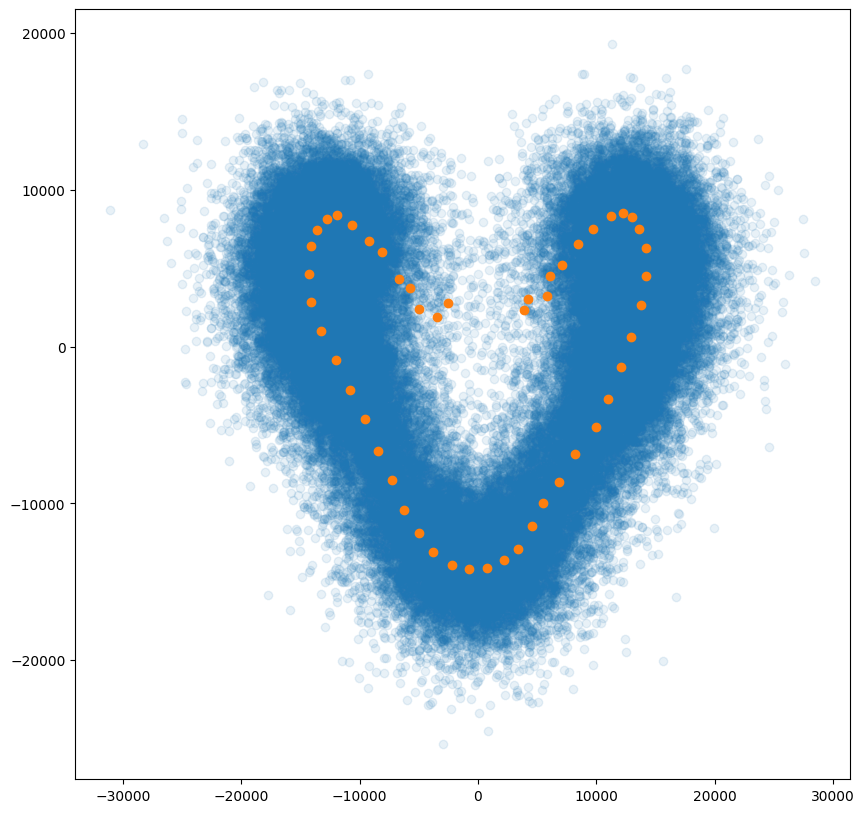

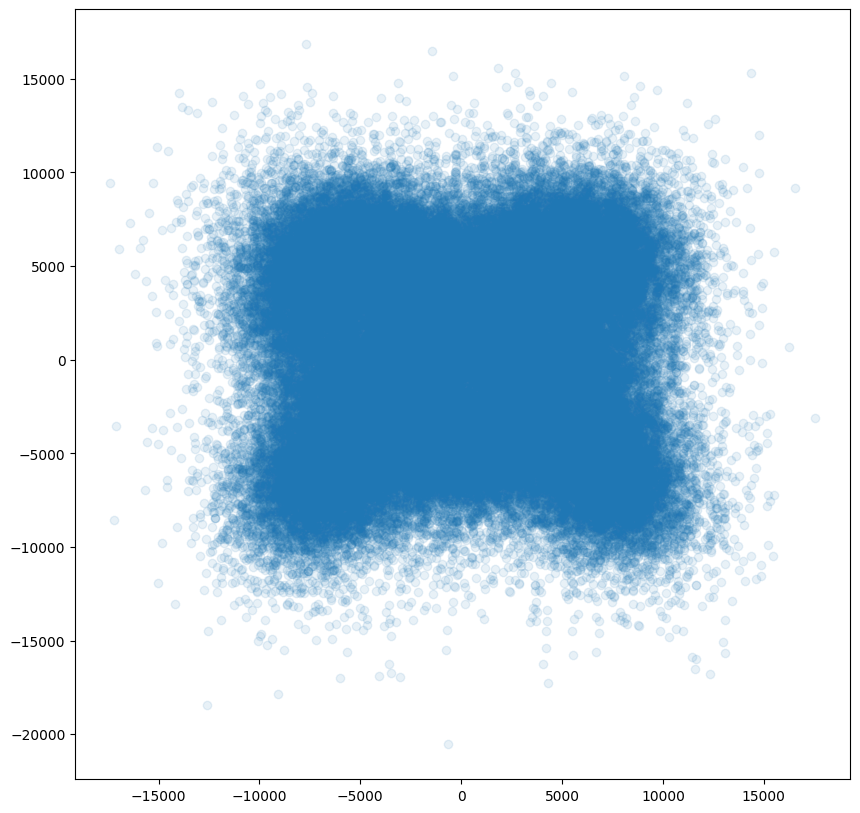

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import joblib

embedding = joblib.load('/tigress/CRYOEM/singerlab/matias_test2/density_test/cryoem_test.joblib')
sim_info = joblib.load('/tigress/CRYOEM/singerlab/matias_test2/density_test/noise1/test_dataset/simulation_info.joblib')

load_dim = 10
zdim_key = f'{load_dim}_noreg'
points = embedding['zs'][zdim_key]
covariances_inv = embedding['cov_zs'][zdim_key]
dim = 4
points = points[:,:dim]
covariances_inv = covariances_inv[:, :dim, :dim]

labels = sim_info['image_assignment']

## Throw away bad points?
covariances = np.linalg.inv(covariances_inv)

#Throw away the top 1% with larger variances
variances = np.trace(covariances, axis1=1, axis2=2)
variances_threshold = np.percentile(variances, 99)

covariances = covariances[variances < variances_threshold]

## These are the samples of the NOISY distribution
points = points[variances < variances_threshold]
labels = labels[variances < variances_threshold]

# Average covariance to use as the kernel
covariances_mean = np.mean(covariances, axis=0)

# Sample from the kernel
from scipy.stats import multivariate_normal
samples = multivariate_normal(np.zeros(dim), covariances_mean).rvs(size=1000)

# Plot the samples of the noisy distribution
plt.scatter(samples[:, 0], samples[:, 1])
plt.show()

prob = np.bincount(labels) / len(labels)
plt.hist(labels, bins = 50)
plt.figure()
plt.plot(prob)

# See noisy distribution looks like
plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.1)

# plt.figure(figsize=(10, 10))

zs = np.zeros((prob.shape[0], dim))
for i in range(prob.shape[0]):
    zs[i] = np.mean(points[labels == i], axis = 0)
    
    
plt.scatter(zs[:, 0], zs[:, 1], alpha=1)
plt.show()



plt.figure(figsize=(10, 10))
plt.scatter(points[:, 2], points[:, 3], alpha=0.1)
plt.show()


# running ttde

In [37]:
from ttde.all_imports import *
from ttde.score.all_imports import *
from ttde.score.experiment_setups.data_setups import NAME_TO_DATASET
from ttde.dl_routine import batched_vmap

from typing import Optional
from flax import struct, linen as lenin
from flax.training import checkpoints
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from jax import vmap
import numpy as np
import click
import optax
import os
import re
from functools import partial
from typing import Optional
from jax.scipy.special import logsumexp

os.environ["WANDB_MODE"] = "offline"

In [38]:
def plot_2d_marginal(
    data,
    dens,
    title,
    dims=(0, 1),
    n_points=200,
    n_rest=1000,
    rest_limits=(points.min(), points.max()),
    batch_size=4096,
    key_seed=0,
):
    """
    Approximate and plot the marginal p(x_i, x_j) for a D-dimensional density.
    """
    D = data.shape[1]
    i, j = dims

    # build the 2-D grid
    xmin, xmax = min(data[:,i]), max(data[:,i])
    ymin, ymax = min(data[:,j]), max(data[:,j])
    x_vals = jnp.linspace(xmin, xmax, n_points)
    y_vals = jnp.linspace(ymin, ymax, n_points)
    XX, YY = jnp.meshgrid(x_vals, y_vals, indexing='xy')
    grid_xy = jnp.stack([XX.ravel(), YY.ravel()], axis=-1)

    # sample the other D-2 dims
    key = jax.random.PRNGKey(key_seed)
    rest_dim = D - 2
    c, d = rest_limits
    rest_samples = jax.random.uniform(key, (n_rest, rest_dim), minval=c, maxval=d)

    # create full points
    def make_full_points(xy):
        out = jnp.zeros((n_rest, D))
        idxs = [k for k in range(D) if k not in dims]
        out = out.at[:, idxs].set(rest_samples)
        out = out.at[:, i].set(xy[0])
        out = out.at[:, j].set(xy[1])
        return out

    batched_make = jax.vmap(make_full_points, in_axes=(0,))
    all_points = batched_make(grid_xy)
    flat_points = all_points.reshape(-1, D)

    ps = dens(flat_points)

    # average over rest dims
    # marginals = jnp.mean(ps.reshape(n_points**2, n_rest), axis=1)
    # Z = jnp.array(marginals).reshape(n_points, n_points)
    
    rest_volume = (rest_limits[1] - rest_limits[0]) ** (D-2)
    marginals = jnp.mean(ps.reshape(n_points**2, n_rest), axis=1) * rest_volume
    Z = marginals.reshape(n_points, n_points)

    # --- normalization check ---
    # compute grid spacings
    dx = (xmax - xmin) / (n_points - 1)
    dy = (ymax - ymin) / (n_points - 1)
    total_mass = jnp.sum(Z) * dx * dy
    print(f"Estimated integral of p(x_{i},x_{j}) over grid: {total_mass:.6f}")
    
    # plot
    plt.figure(figsize=(6, 5))
    plt.imshow(Z, extent=(xmin, xmax, ymin, ymax), origin='lower', aspect='auto')
    plt.colorbar(label=f'p(x_{i}, x_{j})')
    plt.xlabel(f'x_{i}')
    plt.ylabel(f'x_{j}')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    # return Z

In [39]:
# #from flax import struct, linen as lenin

@struct.dataclass
class MonteCarloLLLoss:
    num_mc: int = 128           # Monte‑Carlo samples per data point
    seed:   int = 0             # RNG seed

    def __call__(self,
                 model: lenin.Module,
                 params,
                 xs:    jnp.ndarray,     # shape (B, d)
                 batch_sz: Optional[int] = None
                ) -> float:
        """
        Estimates 
            -1/N ∑ᵢ log [ ∫ q_θ(x) ϕσ(x - yᵢ) dx ]
        by sampling num_mc points from N(yᵢ, σ²I) for each yᵢ,
        and using a log‑mean‑exp estimator.
        """
        key = jax.random.PRNGKey(self.seed)
        B, D = xs.shape

        # 1) draw eps ~ N(0,σ²I), shape (B, num_mc, D)
        key, sub = jax.random.split(key)
        eps = multivariate_normal(np.zeros(D), covariances_mean).rvs(size=(B, self.num_mc))

        # 2) form samples: yᵢ + epsᵢⱼ
        samp = xs[:, None, :] + eps      # (B, num_mc, D)
        flat = samp.reshape((-1, D))     # (B*num_mc, D)

        # 3) eval log_p at all samples
        def log_p(x):
            return model.apply(params, x, method=model.log_p)
        logps_flat = vmap(log_p)(flat)   # (B*num_mc,)

        # 4) reshape and compute log‑mean‑exp
        logps = logps_flat.reshape((B, self.num_mc))
        # log [ (1/K) ∑ⱼ exp(logps_{i,j}) ]
        log_conv = logsumexp(logps, axis=1) - jnp.log(self.num_mc)

        # 5) return -mean log_conv
        return - jnp.mean(log_conv)


In [40]:
N, d = points.shape
n_test = int(0.1 * N)
n_val  = int(0.1 * (N - n_test))

data_test_old  = points[-n_test:]
data_rem   = points[: -n_test]
data_val_old   = data_rem[-n_val:]
data_train_old = data_rem[: -n_val]

data_test = TensorDatasetX(data_test_old).to_jax()
data_val = TensorDatasetX(data_val_old).to_jax()
data_train = TensorDatasetX(data_train_old).to_jax()

In [41]:
# q, m, rank, n_comps = 2, 32, 16, 1
# em_steps, batch_sz, noise, train_noise, lr = 10, 2048, 0.01, 0.01, 0.001

q, m, rank, n_comps = 2, 16, 16, 32
em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.01, 0.001

In [42]:
MODEL = model_setups.PAsTTSqrOpt(q=q, m=m, rank=rank, n_comps=n_comps)
INIT = init_setups.CanonicalRankK(em_steps=em_steps, noise=noise)
TRAINER = trainer_setups.Trainer(batch_sz=batch_sz, lr=lr, noise=train_noise)

WORK_DIR = Path(f'/tigress/CRYOEM/singerlab/matias_test2/density_test/work_dir/cryoemnb/{MODEL}/{INIT}/{TRAINER}')

In [43]:
model = MODEL.create(KEY_0, data_train.X)
init_params = INIT(model, KEY_0, data_train.X)

optimizer = riemannian_optimizer.FlaxWrapper.create(optax.adam(learning_rate=TRAINER.lr), target=init_params)

initializing bases...
initializing model...
creating permutations...
creating PAsTTSqrOpt...
creating first params...
initializing canonical...
rank1 init for em...
em...
adding noise...


In [44]:
trainer = Trainer(
    model=model,
    optim_state=optimizer,
    loss_fn=MonteCarloLLLoss(num_mc=128),
    # loss_fn=LLLoss(),
    #loss_fn=ConvLLLoss(cvrnc=covariances_mean),
    post_processing=MODEL.postprocessing,
    data_train=data_train,
    data_val=data_val,
    batch_sz=TRAINER.batch_sz,
    noise=TRAINER.noise,
    work_dir=utils.suffix_with_date(WORK_DIR),
)

In [45]:
train_steps = 100
trainer.fit(KEY_0, train_steps)

  0%|          | 0/100 [00:00<?, ?it/s]/home/ma4473/.conda/envs/tt-de/lib/python3.9/site-packages/scipy/stats/_multivariate.py:757: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  out = random_state.multivariate_normal(mean, cov, size)
39.1378: 100%|██████████| 100/100 [00:10<00:00,  9.58it/s]


train/custom_loss,█▄▂▂▂▂▂▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/log_int_p,▁▁▃▄▅▅▆▆▆▇▇▇▇▇▇█████████████████████████
train/loglikelihood,▁▅▇▇███████▇██▇█▇▇▇█▇▇▇▇▇▇▇▇▇▇▇▇█▇▇▇▇▇▇▇
train/median_ll,▁▅▇▇▇██████▇██▇████████▇█▇███▇▇▇██▇█▇▇██
train/nonpositive,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/tt_log_sqr_norm,▁▁▂▂▃▄▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█████████████████
train/custom_loss,39.13776
train/log_int_p,22.33967
train/loglikelihood,-39.54128
train/median_ll,-38.6867
train/nonpositive,0.0


In [46]:
base = Path('/tigress/CRYOEM/singerlab/matias_test2/density_test/work_dir/cryoemnb')
if not base.exists():
    raise click.ClickException(f"Work path {base} does not exist")
cpts_dirs = list(base.rglob('cpts'))
if not cpts_dirs:
    raise click.ClickException(f"No 'cpts' folder found under {base}")
ckpt_dir = max(cpts_dirs, key=lambda p: len(str(p)))
click.echo(f"Using checkpoint directory: {ckpt_dir}")

Using checkpoint directory: /tigress/CRYOEM/singerlab/matias_test2/density_test/work_dir/cryoemnb/PAsTTSqrOpt_q=2_m=32_rank=16_n_comps=16/CanonicalRankK_em_steps=10_noise=0.01/Trainer_batch_sz=2048_noise=0.01_lr=0.001/2026-09-14_15:34:21.179133/cpts


In [47]:
params = {
    'q':          q,
    'm':          m,
    'rank':       rank,
    'n_comps':    n_comps,
    'em_steps':   em_steps,
    'noise':      noise,
    'batch_sz':   batch_sz,
    'train_noise': train_noise,
    'lr':         lr,
}

In [48]:
# Build
MODEL = model_setups.PAsTTSqrOpt(q=q, m=m, rank=rank, n_comps=n_comps)
INIT = init_setups.CanonicalRankK(em_steps=em_steps, noise=noise)
TRAINER = trainer_setups.Trainer(batch_sz=batch_sz, lr=lr, noise=train_noise)

key = jax.random.PRNGKey(0)
model = MODEL.create(key, data_train.X)
init_params = INIT(model, key, data_train.X)

optimizer = riemannian_optimizer.FlaxWrapper.create(optax.adam(learning_rate=TRAINER.lr), target=init_params)
restored_state = checkpoints.restore_checkpoint(ckpt_dir=ckpt_dir, target=optimizer, parallel=False)
restored_state = jax.tree_map(jnp.array, restored_state)

params = restored_state.target
log_norm = model.apply(params, method=model.tt_log_sqr_norm)
click.echo(f'Log square norm: {log_norm:.4e}')

initializing bases...
initializing model...
creating permutations...
creating PAsTTSqrOpt...
creating first params...
initializing canonical...
rank1 init for em...
em...
adding noise...
Log square norm: -1.3599e+01


In [49]:
model.apply(params,zs[0],method=model.p)

Array(4.42408e-19, dtype=float32)

In [50]:
p_est = batched_vmap(lambda x: model.apply(params, x, method=model.p), batch_sz)

prob_est_1comp = p_est(zs)

In [51]:
p_est = batched_vmap(lambda x: model.apply(params, x, method=model.p), batch_sz)

prob_est = p_est(zs)

In [52]:
# from scipy.interpolate import interp1d
# kde_probs = np.loadtxt('/home/ma4473/TTDE/kde_probs.csv', delimiter=',')
# prob_kde_fixed = interp1d(kde_probs[:,0], kde_probs[:,1])(list(range(1,49)))
prob_est_fixed = prob_est[1:-1]/np.sum(prob_est[1:-1])
prob_fixed = prob[1:-1]

prob_est_1comp_fixed = prob_est_1comp[1:-1]/np.sum(prob_est_1comp[1:-1])

In [53]:
my_l2 = np.linalg.norm(prob_est_fixed-prob_fixed)/np.linalg.norm(prob_fixed)
# kde_l2 = np.linalg.norm(prob_kde_fixed-prob_fixed)/np.linalg.norm(prob_fixed)
l2_1comp = np.linalg.norm(prob_est_1comp_fixed-prob_fixed)/np.linalg.norm(prob_fixed)
print(my_l2)
print(l2_1comp)

0.6189510188253854
0.6189510188253854


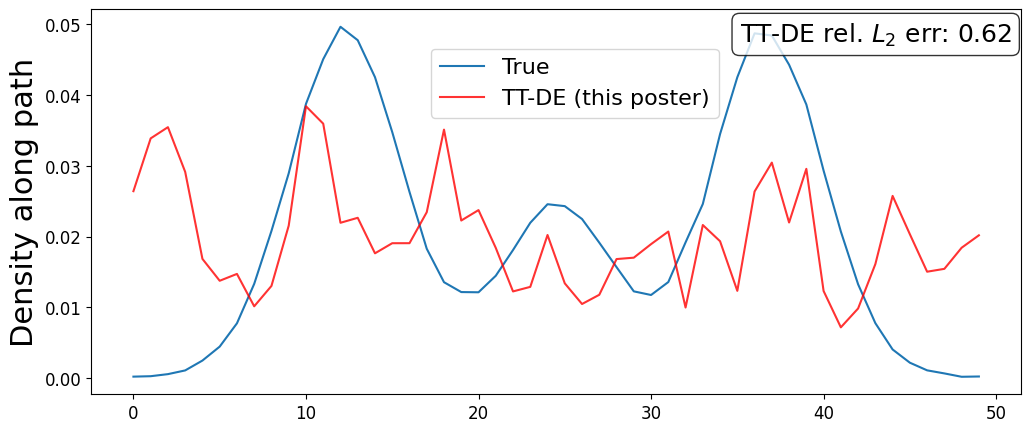

In [54]:
prob_est = p_est(zs)
plt.figure(figsize=(12,5))
plt.plot(prob, label='True')
plt.plot(prob_est / np.sum(prob_est), label='TT-DE (this poster)', alpha=0.8, color='red')
#plt.plot(kde_probs[:,0], kde_probs[:,1], label='KDE', alpha=0.5, color='green')
plt.ylabel('Density along path', fontsize=22)

#plt.text(
#     0.99, 0.97, f'TT-DE rel. $L_2$ err: {my_l2:.2g} \n KDE rel. $L_2$ err: {kde_l2:.2g}',
#     transform=plt.gca().transAxes,
#     fontsize=18,
#     verticalalignment='top',
#     horizontalalignment='right',
#     bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
# )
plt.text(
    0.99, 0.97, f'TT-DE rel. $L_2$ err: {my_l2:.2g}',
    transform=plt.gca().transAxes,
    fontsize=18,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=16, bbox_to_anchor=(0.52, 0.69))
plt.savefig('/home/ma4473/TTDE/dens_along_path.png', dpi=300)

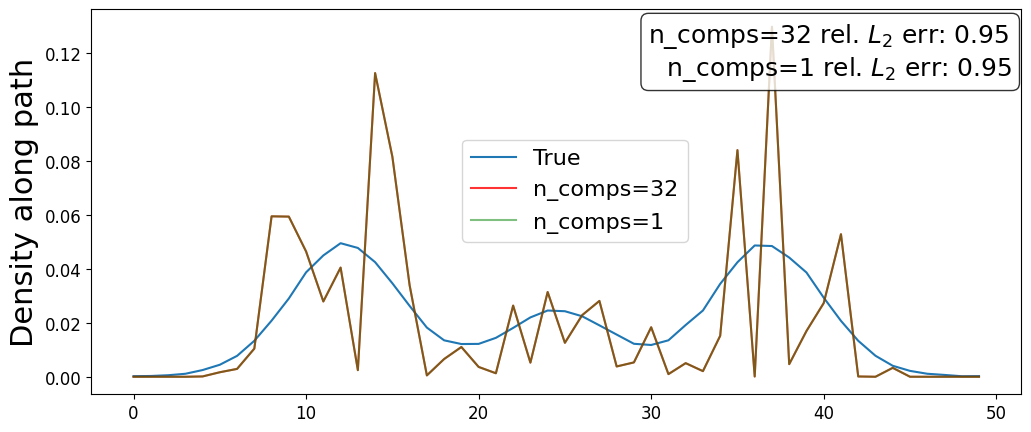

In [21]:
plt.figure(figsize=(12,5))
plt.plot(prob, label='True')
plt.plot(prob_est / np.sum(prob_est), label='n_comps=32', alpha=0.8, color='red')
plt.plot(prob_est_1comp / np.sum(prob_est_1comp), label='n_comps=1', alpha=0.5, color='green')
plt.ylabel('Density along path', fontsize=22)

plt.text(
    0.99, 0.97, f'n_comps=32 rel. $L_2$ err: {my_l2:.2g} \n n_comps=1 rel. $L_2$ err: {l2_1comp:.2g}',
    transform=plt.gca().transAxes,
    fontsize=18,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=16, bbox_to_anchor=(0.52, 0.69))
plt.savefig('/home/ma4473/TTDE/dens_along_path.png', dpi=300)

Estimated integral of p(x_0,x_1) over grid: 0.000000


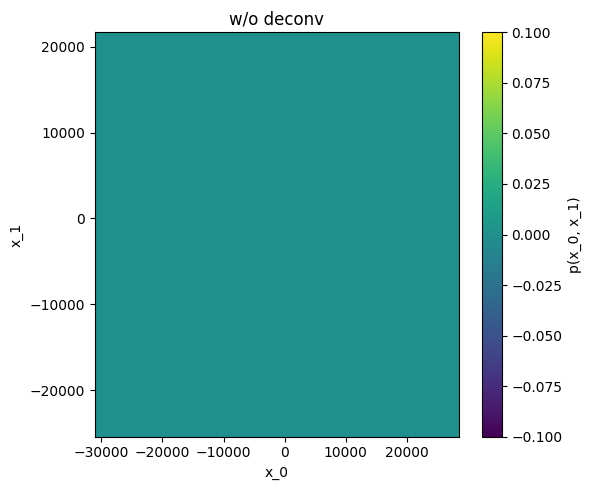

In [81]:
# using q, m, rank, n_comps, training_steps, n_mc = 2, 16, 16, 32, 100, 128
# em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.01, 0.001

plot_2d_marginal(points, p_est, 'w/o deconv', dims=(0,1), batch_size=batch_sz)

Estimated integral of p(x_0,x_1) over grid: 0.809780


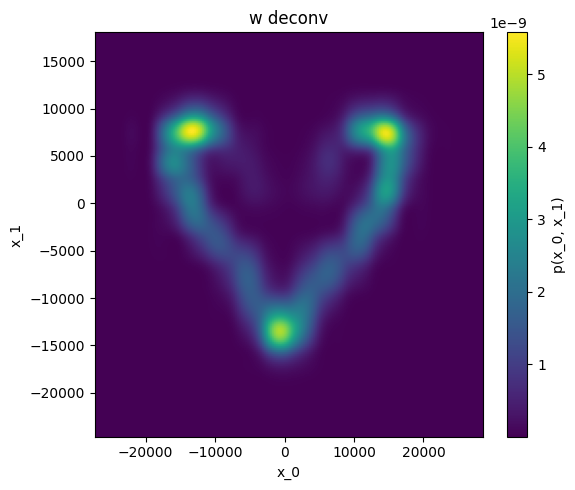

In [99]:
# using q, m, rank, n_comps, training_steps, num_mc = 2, 16, 16, 32, 100, 128
# em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.08, 0.001

plot_2d_marginal(points, p_est, 'w deconv', dims=(0,1), batch_size=batch_sz)

Estimated integral of p(x_0,x_1) over grid: 0.861861


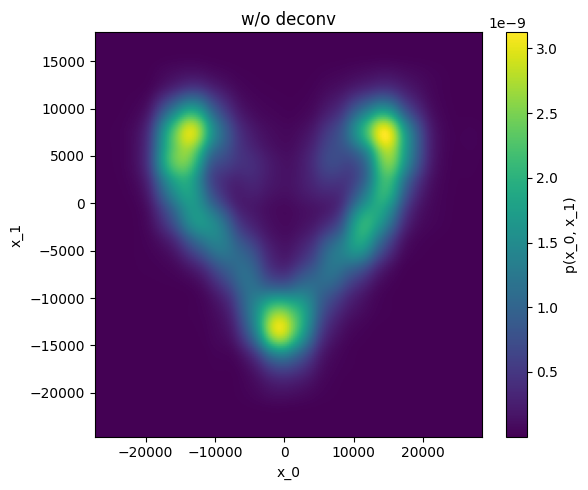

In [114]:
# using q, m, rank, n_comps, training_steps, n_mc = 2, 16, 16, 32, 100, na
# em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.08, 0.001

plot_2d_marginal(points, p_est, 'w/o deconv', dims=(0,1), batch_size=batch_sz)

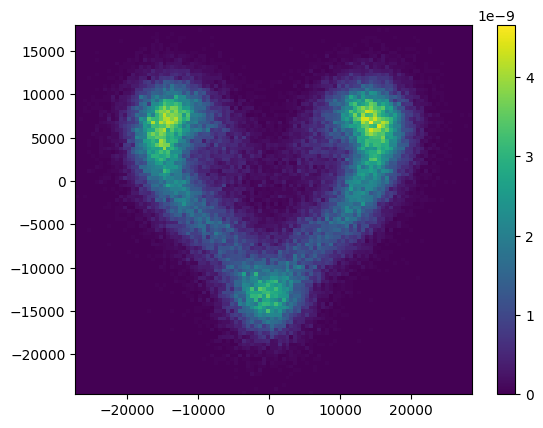

In [100]:
plt.hist2d(points[:,0], points[:,1], bins=100, density=True)
plt.colorbar();

In [1]:
# using q, m, rank, n_comps, training_steps, n_mc = 2, 16, 16, 32, 100, 128
# em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.08, 0.001

plot_2d_marginal(points, p_est, 'w deconv', dims=(2,3), batch_size=batch_sz)

NameError: name 'plot_2d_marginal' is not defined

Estimated integral of p(x_2,x_3) over grid: 0.903035


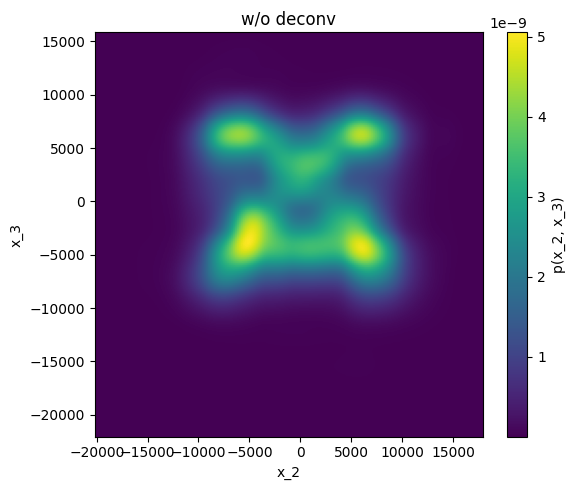

In [115]:
# using q, m, rank, n_comps, training_steps, n_mc = 2, 16, 16, 32, 100, 128
# em_steps, batch_sz, noise, train_noise, lr = 10, 512, 0.01, 0.08, 0.001

plot_2d_marginal(points, p_est, 'w/o deconv', dims=(2,3), batch_size=batch_sz)

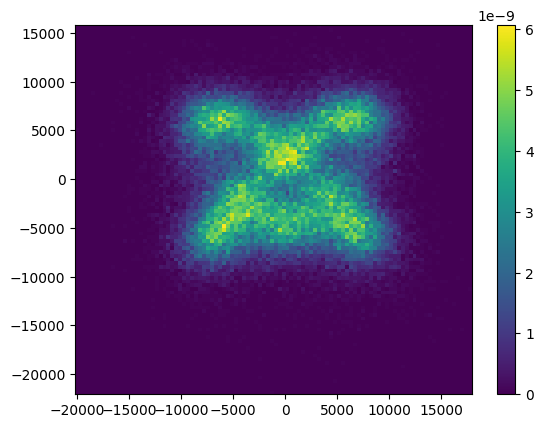

In [102]:
plt.hist2d(points[:,2], points[:,3], bins=100, density=True)
plt.colorbar();

In [44]:
i, j = 0, 1

p_est = batched_vmap(lambda x: model.apply(params, x, method=model.p), batch_sz)
Z_est01 = plot_2d_marginal(points, p_est, 'na', dims=(i,j), batch_size=batch_sz)

k, l = 2, 3
Z_est23 = plot_2d_marginal(points, p_est, 'na', dims=(k,l), batch_size=batch_sz)

Estimated integral of p(x_0,x_1) over grid: 0.811176
Estimated integral of p(x_2,x_3) over grid: 0.856985


In [49]:
i, j = 0, 1

p_est = batched_vmap(lambda x: model.apply(params, x, method=model.p), batch_sz)
Z_est_raw01 = plot_2d_marginal(points, p_est, 'na', dims=(i,j), batch_size=batch_sz)

k, l = 2, 3
Z_est_raw23 = plot_2d_marginal(points, p_est, 'na', dims=(k,l), batch_size=batch_sz)

Estimated integral of p(x_0,x_1) over grid: 0.861795
Estimated integral of p(x_2,x_3) over grid: 0.903091


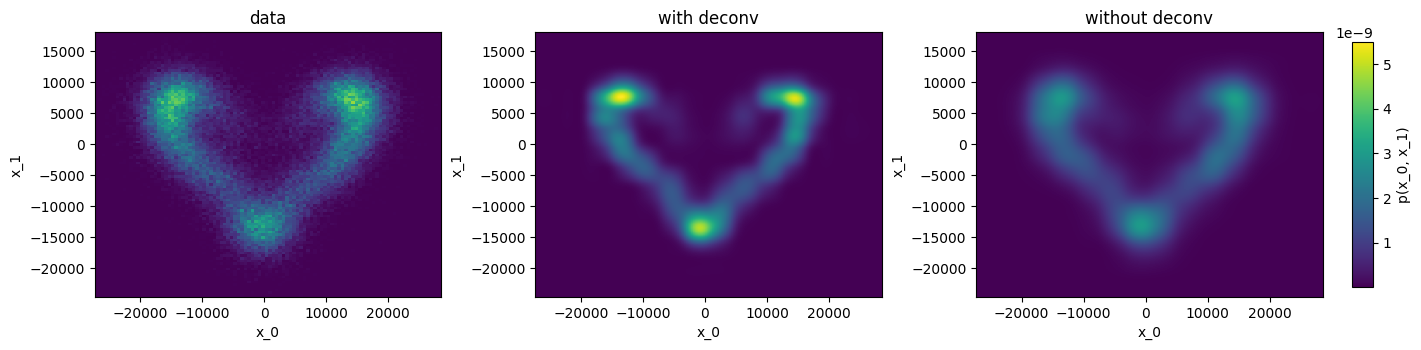

In [90]:
fig.clf()

xmin, xmax = points[:,i].min(), points[:,i].max()
ymin, ymax = points[:,j].min(), points[:,j].max()

vmin = float(jnp.minimum(Z_est01.min(), Z_est_raw01.min()))
vmax = float(jnp.maximum(Z_est01.max(), Z_est_raw01.max()))

span_x = xmax - xmin
span_y = ymax - ymin
height = 5                              # inches
single_width = height * (span_x / span_y)
total_width = single_width * 2 + 1.0    # +1in for colorbar
fig, axes = plt.subplots(
    1, 3,
    figsize=(total_width, height),
    constrained_layout=True
)

# plot true
h, xedges, yedges, im0 = axes[0].hist2d(
    points[:, i], points[:, j],
    bins=100,
    range=[[xmin, xmax], [ymin, ymax]],
    density=True,
    cmap='viridis',          # optional: match imshow colormap
    vmin=vmin,
    vmax=vmax
)
axes[0].set(
    title='data',
    xlabel=f'x_{i}',
    ylabel=f'x_{j}',
    aspect='equal',
    xlim=(xmin, xmax),
    ylim=(ymin, ymax)
)

# plot est
im1 = axes[1].imshow(
    Z_est01,
    extent=(xmin, xmax, ymin, ymax),
    origin='lower',
    aspect='equal',     # square pixels
    vmin=vmin, vmax=vmax
)
axes[1].set(title='with deconv', xlabel=f'x_{i}', ylabel=f'x_{j}')

# plot est raw
im2 = axes[2].imshow(
    Z_est_raw01,
    extent=(xmin, xmax, ymin, ymax),
    origin='lower',
    aspect='equal',
    vmin=vmin, vmax=vmax
)
axes[2].set(title='without deconv', xlabel=f'x_{i}', ylabel=f'x_{j}')

# shared colorbar on the right
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation='vertical',
    aspect=12,      # colorbar thickness
    pad=0.01,           # space between plots and bar
    shrink=0.5          # making it shorter
)
cbar.set_label(f'p(x_{i}, x_{j})')

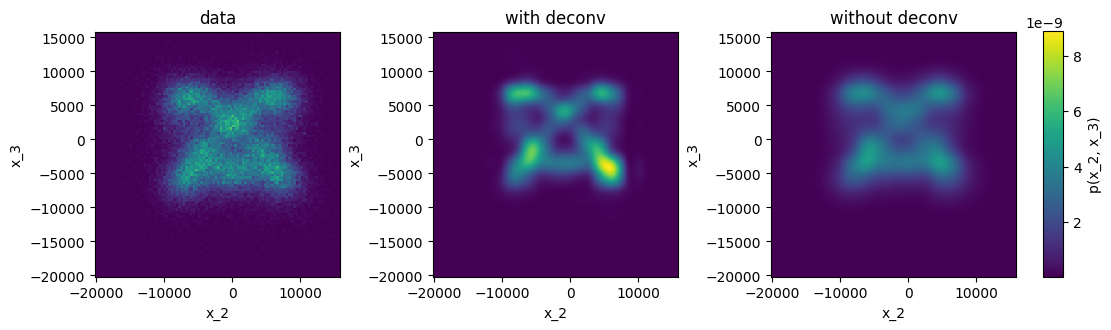

In [88]:
fig.clf()

xmin, xmax = points[:,k].min(), points[:,l].max()
ymin, ymax = points[:,k].min(), points[:,l].max()

vmin = float(jnp.minimum(Z_est23.min(), Z_est_raw23.min()))
vmax = float(jnp.maximum(Z_est23.max(), Z_est_raw23.max()))

span_x = xmax - xmin
span_y = ymax - ymin
height = 5                              # inches
single_width = height * (span_x / span_y)
total_width = single_width * 2 + 1.0    # +1in for colorbar
fig, axes = plt.subplots(
    1, 3,
    figsize=(total_width, height),
    constrained_layout=True
)

# plot true
h, xedges, yedges, im0 = axes[0].hist2d(
    points[:, k], points[:, l],
    bins=100,
    range=[[xmin, xmax], [ymin, ymax]],
    density=True,
    cmap='viridis',          # optional: match imshow colormap
    vmin=vmin,
    vmax=vmax
)
axes[0].set(
    title='data',
    xlabel=f'x_{k}',
    ylabel=f'x_{l}',
    aspect='equal',
    xlim=(xmin, xmax),
    ylim=(ymin, ymax)
)

# plot est
im1 = axes[1].imshow(
    Z_est23,
    extent=(xmin, xmax, ymin, ymax),
    origin='lower',
    aspect='equal',     # square pixels
    vmin=vmin, vmax=vmax
)
axes[1].set(title='with deconv', xlabel=f'x_{k}', ylabel=f'x_{l}')

# plot est raw
im2 = axes[2].imshow(
    Z_est_raw23,
    extent=(xmin, xmax, ymin, ymax),
    origin='lower',
    aspect='equal',
    vmin=vmin, vmax=vmax
)
axes[2].set(title='without deconv', xlabel=f'x_{k}', ylabel=f'x_{l}')

# shared colorbar on the right
cbar = fig.colorbar(
    im1,
    ax=axes,
    orientation='vertical',
    aspect=12,      # colorbar thickness
    pad=0.01,           # space between plots and bar
    shrink=0.5          # making it shorter
)
cbar.set_label(f'p(x_{k}, x_{l})')

In [91]:
fig.savefig("/home/ma4473/TTDE/cryoem_test01.png", dpi=300)

In [16]:

D = points.shape[1]
dims = (0,1)
i, j = 0,1

# build the 2-D grid
# xmin, xmax = min(data[:,i]), max(data[:,i])
# ymin, ymax = min(data[:,j]), max(data[:,j])

xmin, xmax = -22500, 22500
ymin, ymax = -27500, 17500

x_vals = jnp.linspace(xmin, xmax, 200)
y_vals = jnp.linspace(ymin, ymax, 200)
XX, YY = jnp.meshgrid(x_vals, y_vals, indexing='xy')
grid_xy = jnp.stack([XX.ravel(), YY.ravel()], axis=-1)

# sample the other D-2 dims
key = jax.random.PRNGKey(0)
rest_dim = D - 2
c, d = points.min(), points.max()
rest_limits = (points.min(), points.max())
rest_samples = jax.random.uniform(key, (1000, rest_dim), minval=c, maxval=d)

# create full points
def make_full_points(xy):
    out = jnp.zeros((1000, D))
    idxs = [k for k in range(D) if k not in dims]
    out = out.at[:, idxs].set(rest_samples)
    out = out.at[:, i].set(xy[0])
    out = out.at[:, j].set(xy[1])
    return out

batched_make = jax.vmap(make_full_points, in_axes=(0,))
all_points = batched_make(grid_xy)
flat_points = all_points.reshape(-1, D)

ps = p_est(flat_points)

# average over rest dims
# marginals = jnp.mean(ps.reshape(n_points**2, n_rest), axis=1)
# Z = jnp.array(marginals).reshape(n_points, n_points)

rest_volume = (rest_limits[1] - rest_limits[0]) ** (D-2)
marginals = jnp.mean(ps.reshape(200**2, 1000), axis=1) * rest_volume
Z = marginals.reshape(200, 200)

# --- normalization check ---
# compute grid spacings
dx = (xmax - xmin) / (200 - 1)
dy = (ymax - ymin) / (200 - 1)
total_mass = jnp.sum(Z) * dx * dy
print(f"Estimated integral of p(x_{i},x_{j}) over grid: {total_mass:.6f}")

Estimated integral of p(x_0,x_1) over grid: 0.837790


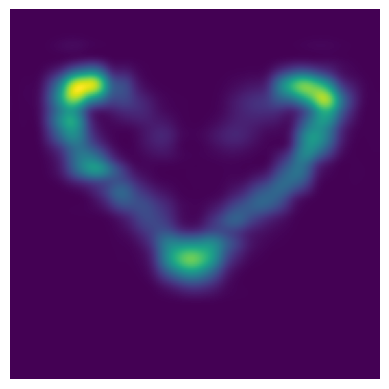

In [17]:

# plot
plt.imshow(Z, extent=(xmin, xmax, ymin, ymax), origin='lower', aspect='equal')
# plt.colorbar(label=f'p(x_{i}, x_{j})')
# plt.xlabel(f'x_{i}')
# plt.ylabel(f'x_{j}')
plt.axis('off')
# plt.title(title)
# plt.title('Conformational density', fontsize=20)
#plt.savefig('/home/ma4473/TTDE/cryoem_embedding_dens.png', dpi=300)
plt.show()
# return Z

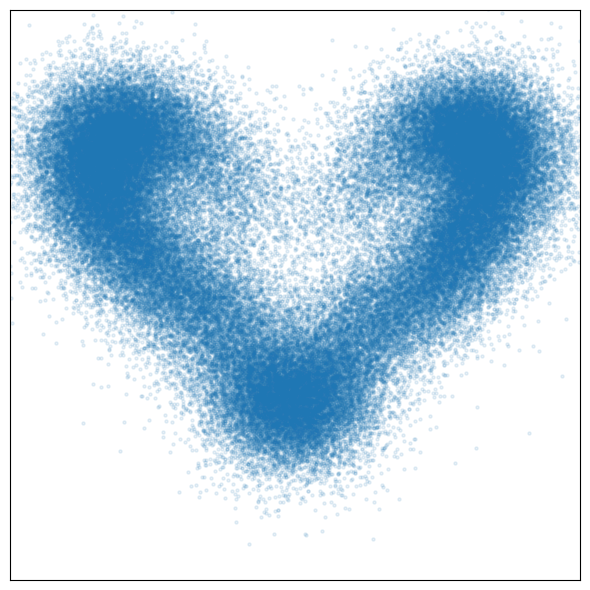

In [35]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.1)

# Hide ticks and labels
ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

# Hide top and right spines
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

# Keep bottom and left spines visible (i.e. frame)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Make aspect square
ax.set_aspect('equal')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.tight_layout()
#plt.savefig('/home/ma4473/TTDE/cryoem_data.png', dpi=300)
plt.show()


In [20]:
samples_plot = multivariate_normal(np.zeros(dim), covariances_mean).rvs(size=10000000)

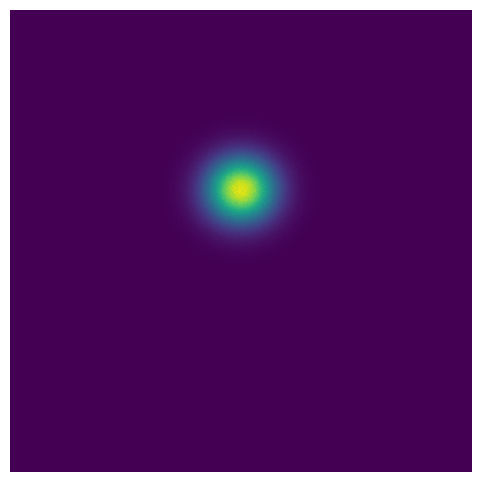

In [36]:
# # Plot the samples of the noisy distribution
# plt.hist2d(samples_plot[:, 0], samples_plot[:, 1], bins=500, cmin=0, vmin=0)
# plt.xlim(xmin,xmax)
# plt.ylim(ymin,ymax)
# plt.show()

H, xedges, yedges = np.histogram2d(
    samples_plot[:, 0],
    samples_plot[:, 1],
    bins=500,
    range=[[xmin, xmax], [ymin, ymax]]
)

# 2) plot with imshow
plt.figure(figsize=(6, 6))
plt.imshow(
    H.T,                        # transpose for correct orientation
    origin='lower',
    extent=(xmin, xmax, ymin, ymax),
    aspect='equal',
)
plt.axis('off')
plt.show()

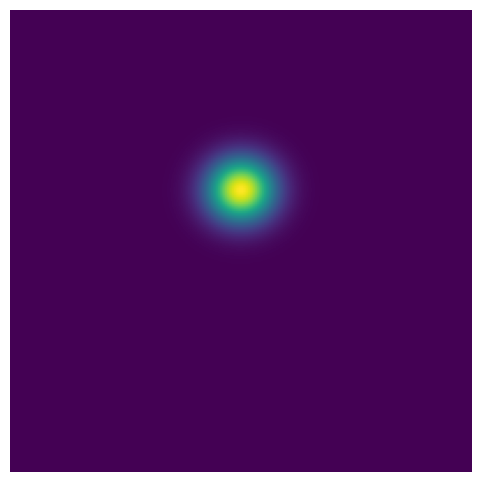

In [283]:
i, j = 0, 1

# Marginalize full covariance to 2D
cov_2d = covariances_mean[[i, j]][:, [i, j]]

# Grid setup
n_points = 200
x = np.linspace(xmin, xmax, n_points)
y = np.linspace(ymin, ymax, n_points)
XX, YY = np.meshgrid(x, y)
grid = np.stack([XX.ravel(), YY.ravel()], axis=-1)  # shape (n_points^2, 2)

# Evaluate true density
mean_2d = np.zeros(2)
pdf_vals = multivariate_normal(mean_2d, cov_2d).pdf(grid)
Z = pdf_vals.reshape(n_points, n_points)

# Plot with imshow
plt.figure(figsize=(6, 6))
plt.imshow(Z, extent=(xmin, xmax, ymin, ymax), origin='lower', aspect='equal')
plt.axis('off')
plt.savefig('/home/ma4473/TTDE/cryoem_embedding_uncertainty.png', dpi=300)
plt.show()


In [19]:

D = points.shape[1]
dims = (2,3)
i, j = 2,3

# build the 2-D grid
# xmin, xmax = min(data[:,i]), max(data[:,i])
# ymin, ymax = min(data[:,j]), max(data[:,j])

xmin, xmax = -15000, 15000
ymin, ymax = -15000, 15000

x_vals = jnp.linspace(xmin, xmax, 200)
y_vals = jnp.linspace(ymin, ymax, 200)
XX, YY = jnp.meshgrid(x_vals, y_vals, indexing='xy')
grid_xy = jnp.stack([XX.ravel(), YY.ravel()], axis=-1)

# sample the other D-2 dims
key = jax.random.PRNGKey(0)
rest_dim = D - 2
c, d = points.min(), points.max()
rest_limits = (points.min(), points.max())
rest_samples = jax.random.uniform(key, (1000, rest_dim), minval=c, maxval=d)

# create full points
def make_full_points(xy):
    out = jnp.zeros((1000, D))
    idxs = [k for k in range(D) if k not in dims]
    out = out.at[:, idxs].set(rest_samples)
    out = out.at[:, i].set(xy[0])
    out = out.at[:, j].set(xy[1])
    return out

batched_make = jax.vmap(make_full_points, in_axes=(0,))
all_points = batched_make(grid_xy)
flat_points = all_points.reshape(-1, D)

ps = p_est(flat_points)

# average over rest dims
# marginals = jnp.mean(ps.reshape(n_points**2, n_rest), axis=1)
# Z = jnp.array(marginals).reshape(n_points, n_points)

rest_volume = (rest_limits[1] - rest_limits[0]) ** (D-2)
marginals = jnp.mean(ps.reshape(200**2, 1000), axis=1) * rest_volume
Z = marginals.reshape(200, 200)

# --- normalization check ---
# compute grid spacings
dx = (xmax - xmin) / (200 - 1)
dy = (ymax - ymin) / (200 - 1)
total_mass = jnp.sum(Z) * dx * dy
print(f"Estimated integral of p(x_{i},x_{j}) over grid: {total_mass:.6f}")

Estimated integral of p(x_2,x_3) over grid: 0.835862


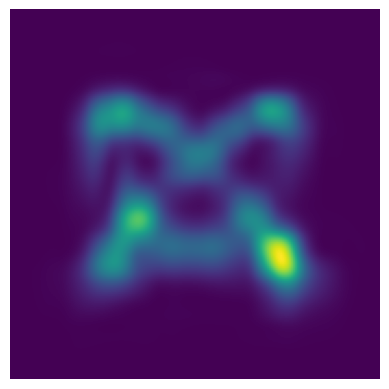

In [23]:

# plot
plt.imshow(Z, extent=(xmin, xmax, ymin, ymax), origin='lower', aspect='equal')
# plt.colorbar(label=f'p(x_{i}, x_{j})')
# plt.xlabel(f'x_{i}')
# plt.ylabel(f'x_{j}')
plt.axis('off')
# plt.title(title)
# plt.title('Conformational density', fontsize=20)
plt.savefig('/home/ma4473/TTDE/cryoem_embedding_dens_23.png', dpi=300)
plt.show()
# return Z

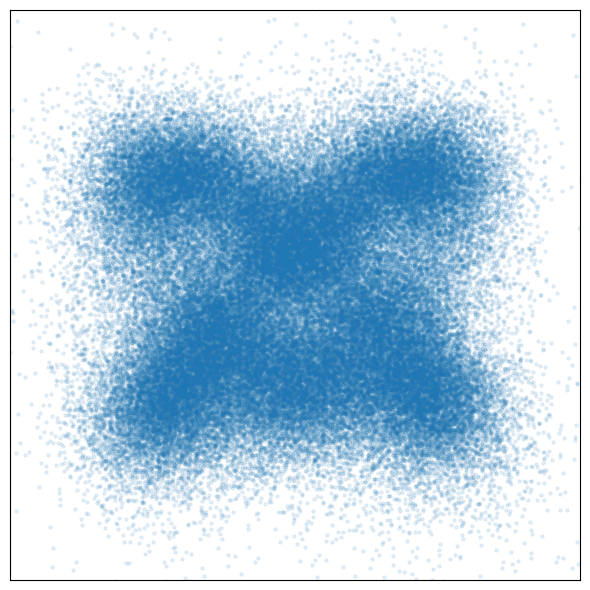

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(points[:, 2], points[:, 3], s=5, alpha=0.1)

# Hide ticks and labels
ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

# Hide top and right spines
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

# Keep bottom and left spines visible (i.e. frame)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Make aspect square
ax.set_aspect('equal')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.tight_layout()
plt.savefig('/home/ma4473/TTDE/cryoem_data_23.png', dpi=300)
plt.show()
